In [1]:
import numpy as np
from toolbox import (
    Masking,
    combined_frequency_roc_analysis,
    compute_ROC,
    find_all_indices,
    hot_coding,
)
from toolbox.loading import load_data

In [2]:
IIVV = np.loadtxt("source/IIVV_patterns.txt", dtype=int)
mask = Masking(IIVV)

In [3]:
(
    py_idx,
    patient_no,
    patient_sample,
    Zdata,
    Avg_Cutpats,
    LesionAssessment,
    labels_healthy_vs_cancer,
    labels_cancer_vs_hbd,
    labels_MC,
) = load_data(path="data", Cutpats_threshold=60, norm="freq")


	Info:	np.abs(Zdata)

Remaining data samples: 244 
	Info:	Select only data Avg_Cutpats <60%

Remaining data samples: 229 

	Info:	z-score Zdata
before: 434.20845093924504 699.3585400487347
Normalized along the frequency axis.

after: -4.3347838749237164e-17 1.000000000000001

	Info:	np.nan_to_num(Zdata)

Remaining data samples: 229 


**Select classification basis task `class_task`**

- `"healthy_vs_cancer"`
- `"cancer_vs_hbd"`
- `"MC"`

In [4]:
class_task = "healthy_vs_cancer"
# class_task = "cancer_vs_hbd"
# class_task = "MC"

In [5]:
if class_task == "healthy_vs_cancer":
    print("Healthy vs. cancer\n")
    select_idx = find_all_indices(
        labels_healthy_vs_cancer, ["Healthy", "Cancer"], split=False
    )
    labels = labels_healthy_vs_cancer[select_idx]

elif class_task == "cancer_vs_hbd":
    print("\nHealthy vs. HDB\n")
    select_idx = find_all_indices(
        labels_cancer_vs_hbd, ["Non-cancer", "Cancer"], split=False
    )
    labels = labels_cancer_vs_hbd[select_idx]
elif class_task == "MC":
    print("\nMC\n")
    select_idx = find_all_indices(
        labels_MC,
        ["Healthy", "Cancer", "Mild dysplasia", "Severe dysplasia", "Benign"],
        split=False,
    )
    labels = labels_MC[select_idx]
Case = patient_no[select_idx]
X = Zdata[select_idx, ...]
Y = hot_coding(labels)

Healthy vs. cancer

Healthy: 89 entries
Cancer: 91 entries
Available cases: ['Cancer' 'Healthy']
Coding: -> forward
{np.str_('Cancer'): [1, 0], np.str_('Healthy'): [0, 1]}


In [6]:
print(X.shape, Y.shape, labels.shape)

(180, 31, 7728) (180, 2) (180,)


NaN are replaced by 0.
(144, 239568) (36, 239568) (144, 2) (36, 2)
Note: Using random sample splitting (not patient-based)


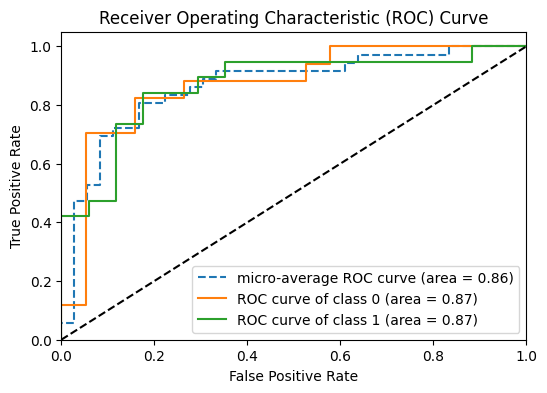

avg_roc_auc=np.float64(0.868421052631579)


(np.float64(0.868421052631579),
 {'roc_auc_0': np.float64(0.8699690402476781),
  'roc_auc_1': np.float64(0.8668730650154798)})

In [7]:
compute_ROC(X[:, :, :], Y, test_size=0.2, plot=True)

## Frequency sweep with ranked frequencies from PCA

**1. All IIVV patterns (baseline)**

In [8]:
random_state = 0

Performing 5-fold cross-validation with PCA-based frequency ranking and ROC analysis...
Train patients: [ 0  1  3  4  6  7 10 11 12 13 15 16 19 20 21 22 23 25 27 28 29 30 31 32
 34 35 37 38 39 40 41 42 43 44 45 46 47 48 49 50 51 52 53 55 56 57 58 60
 61 62 66 67 68 69 70 72 73 74 75 76 77 78 79 81 84 85 86 87 88 89 90 91
 92 95 96 97]
Test patients: [ 2 33 59 18 14 64 65 83 36 82 80  8 54 94 99 63  9 24]
Fold 1: 77.2% train / 22.8% test
Fold 1: 77.2% train / 22.8% test
  Training: 139 samples from 76 patients
  Testing:  41 samples from 18 patients
Fold 1 frequency ranking (top 10): [ 0 30 12 13  8 23 10 16 20 11]
Train patients: [ 0  1  2  4  6  8  9 10 11 12 13 14 15 16 18 19 21 22 23 24 25 28 31 32
 33 34 35 36 37 38 39 40 41 42 43 44 47 49 50 52 53 54 55 56 57 58 59 60
 61 62 63 64 65 66 67 68 70 72 73 74 75 76 79 80 82 83 84 85 87 89 92 94
 95 96 97 99]
Test patients: [77 48 29 46 27  7 45 51 78 86 81 91 90  3 69 88 30 20]
Fold 2: 81.1% train / 18.9% test
Fold 2: 81.1% train / 18.

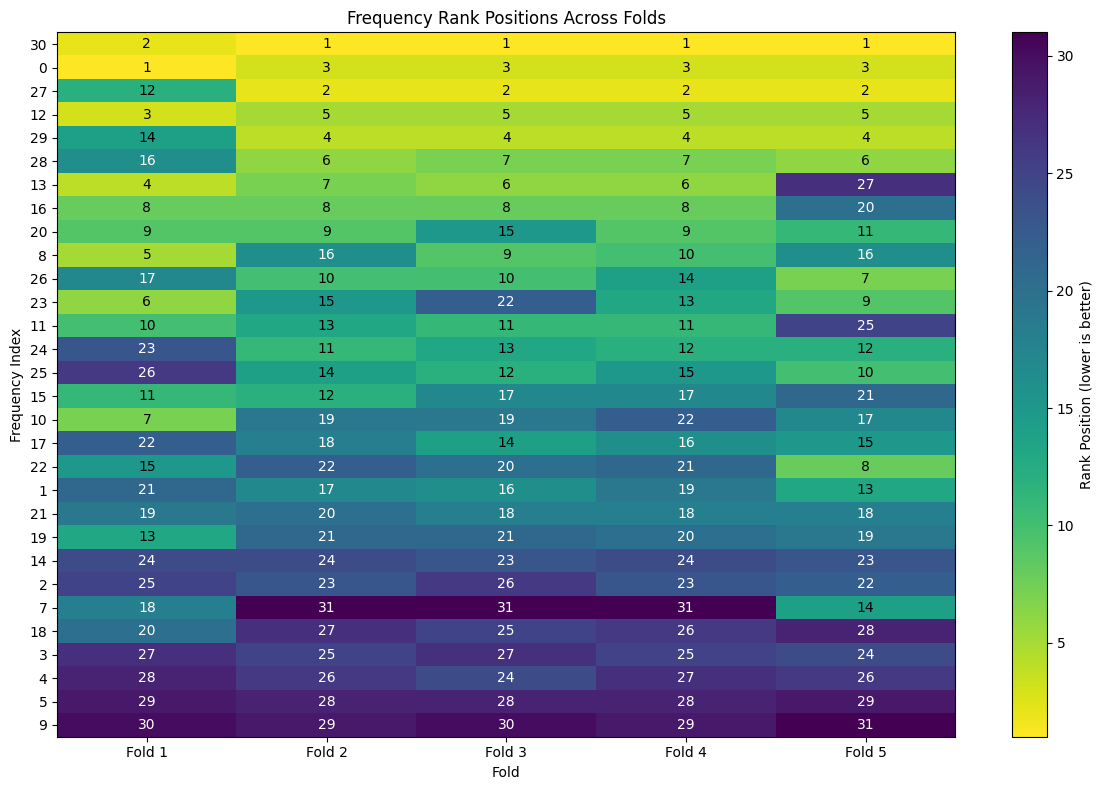

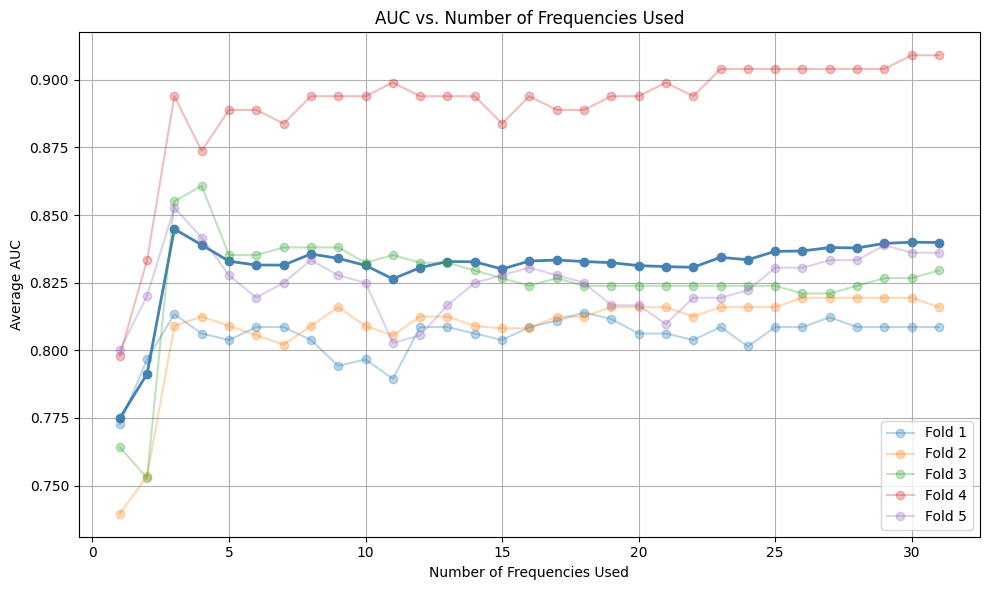

In [9]:
from toolbox.roc_auc import combined_frequency_roc_analysis

aucs_all, top_freqs_all, fold_rankings_all, fold_aucs_all = (
    combined_frequency_roc_analysis(
        X, Y, Case, max_freqs=31, n_folds=5, random_state=random_state
    )
)

___

Testing the different heuristically chosen patterns:

- `mask.IIVV_mask("vv_long_across")`
- `mask.IIVV_mask("vv_long_across_extended")`
- `mask.IIVV_mask("vv_medium_across_extended")`
- `mask.IIVV_mask("vv_distance_close_skip_1")`

**2. Long across `vv_long_across`**

config: vv_long_across=array([[26, 31,  1, 22],
       [26, 31,  1, 21],
       [26, 31,  2, 21],
       [26, 31,  2, 22],
       [27, 30,  4, 24],
       [27, 30,  4, 25],
       [27, 30,  5, 24],
       [27, 30,  5, 25],
       [28, 33,  1,  5],
       [28, 33,  1, 10],
       [28, 33,  5,  6],
       [28, 33,  6, 10],
       [29, 32, 16, 20],
       [29, 32, 16, 25],
       [29, 32, 20, 21],
       [29, 32, 21, 25]])


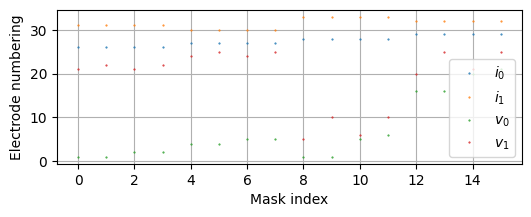

Mask set by IIVV pattern rule.
True: 16 (0.21%)	False: 7712(99.79%)
Performing 5-fold cross-validation with PCA-based frequency ranking and ROC analysis...
Train patients: [ 0  1  3  4  6  7 10 11 12 13 15 16 19 20 21 22 23 25 27 28 29 30 31 32
 34 35 37 38 39 40 41 42 43 44 45 46 47 48 49 50 51 52 53 55 56 57 58 60
 61 62 66 67 68 69 70 72 73 74 75 76 77 78 79 81 84 85 86 87 88 89 90 91
 92 95 96 97]
Test patients: [ 2 33 59 18 14 64 65 83 36 82 80  8 54 94 99 63  9 24]
Fold 1: 77.2% train / 22.8% test
Fold 1: 77.2% train / 22.8% test
  Training: 139 samples from 76 patients
  Testing:  41 samples from 18 patients
Fold 1 frequency ranking (top 10): [ 0 12 30 13 11  1  8 16 10  7]
Train patients: [ 0  1  2  4  6  8  9 10 11 12 13 14 15 16 18 19 21 22 23 24 25 28 31 32
 33 34 35 36 37 38 39 40 41 42 43 44 47 49 50 52 53 54 55 56 57 58 59 60
 61 62 63 64 65 66 67 68 70 72 73 74 75 76 79 80 82 83 84 85 87 89 92 94
 95 96 97 99]
Test patients: [77 48 29 46 27  7 45 51 78 86 81 91 90  3 69 

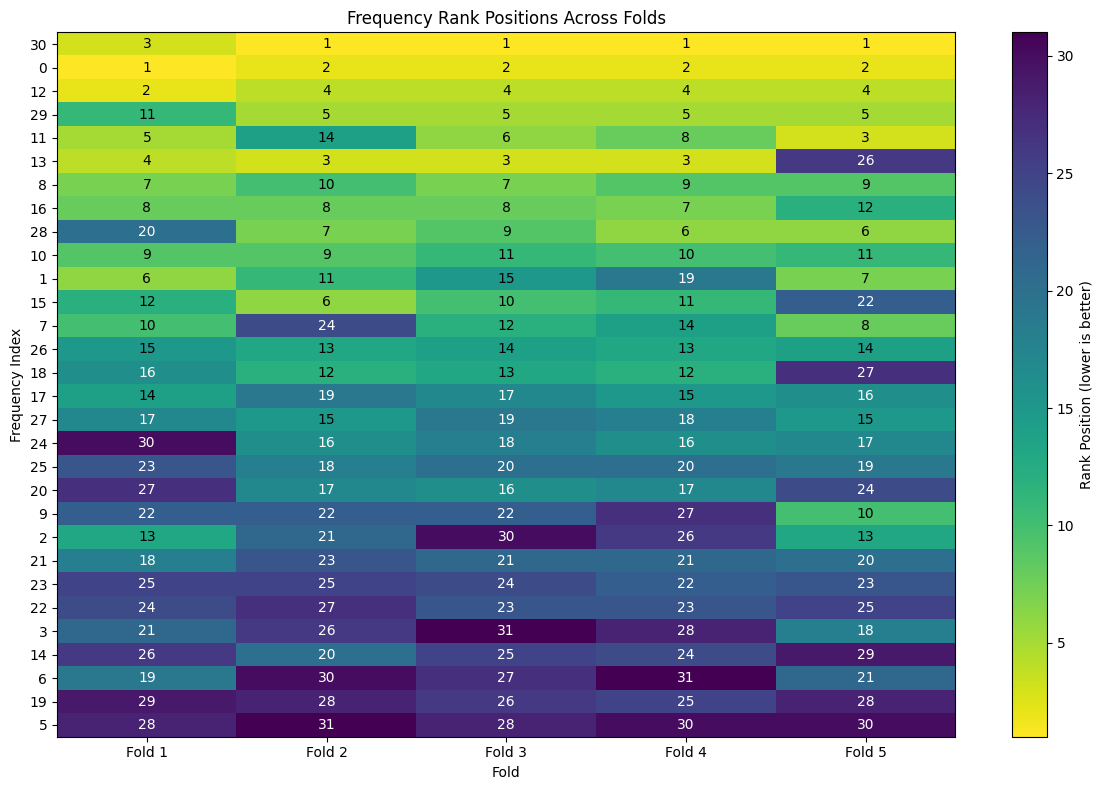

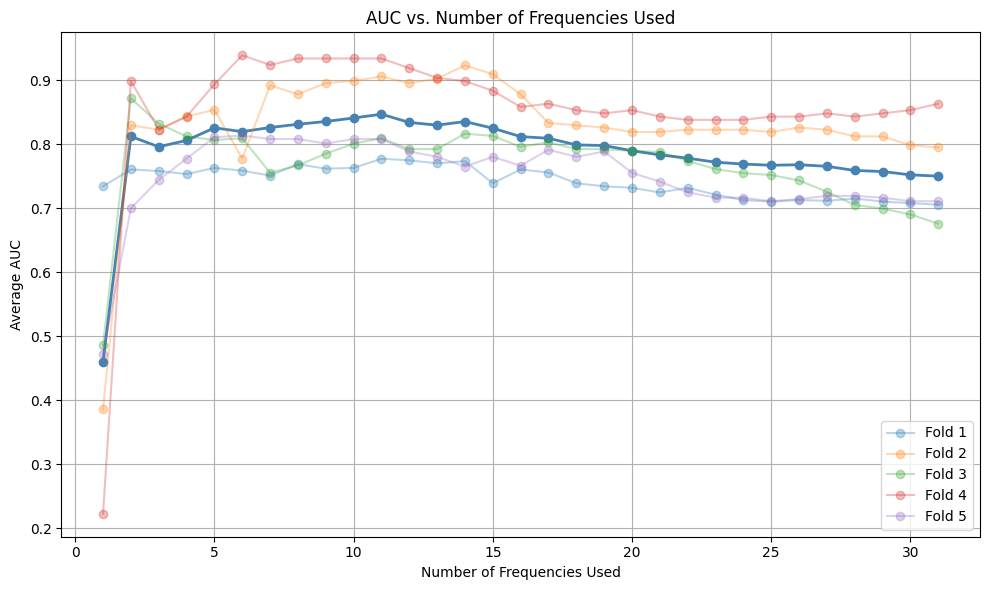

In [10]:
mask.IIVV_mask("vv_long_across")
X_tmp = X[:, :, mask.mask]

aucs_la, top_freqs_la, fold_rankings_la, fold_aucs_la = combined_frequency_roc_analysis(
    X_tmp, Y, Case, max_freqs=31, n_folds=5, random_state=random_state
)

**3. Long across extended `vv_long_across_extended`**

config: vv_long_across_extended={'26_31': [1, 2, 3, 21, 22, 23], '27_30': [3, 4, 5, 23, 24, 25], '28_33': [1, 5, 6, 10, 11, 15], '29_32': [11, 15, 16, 20, 21, 25], '30_26': [1, 2, 3, 23, 24, 25], '31_27': [3, 4, 5, 21, 22, 23], '32_28': [5, 10, 11, 15, 16, 21], '33_29': [1, 6, 11, 15, 20, 25]}


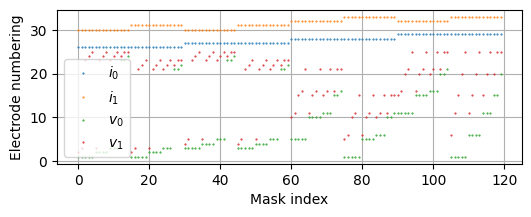

Mask set by IIVV pattern rule.
True: 120 (1.55%)	False: 7608(98.45%)
Performing 5-fold cross-validation with PCA-based frequency ranking and ROC analysis...
Train patients: [ 0  1  3  4  6  7 10 11 12 13 15 16 19 20 21 22 23 25 27 28 29 30 31 32
 34 35 37 38 39 40 41 42 43 44 45 46 47 48 49 50 51 52 53 55 56 57 58 60
 61 62 66 67 68 69 70 72 73 74 75 76 77 78 79 81 84 85 86 87 88 89 90 91
 92 95 96 97]
Test patients: [ 2 33 59 18 14 64 65 83 36 82 80  8 54 94 99 63  9 24]
Fold 1: 77.2% train / 22.8% test
Fold 1: 77.2% train / 22.8% test
  Training: 139 samples from 76 patients
  Testing:  41 samples from 18 patients
Fold 1 frequency ranking (top 10): [ 0 30 12 13 15  8 11 10 16 17]
Train patients: [ 0  1  2  4  6  8  9 10 11 12 13 14 15 16 18 19 21 22 23 24 25 28 31 32
 33 34 35 36 37 38 39 40 41 42 43 44 47 49 50 52 53 54 55 56 57 58 59 60
 61 62 63 64 65 66 67 68 70 72 73 74 75 76 79 80 82 83 84 85 87 89 92 94
 95 96 97 99]
Test patients: [77 48 29 46 27  7 45 51 78 86 81 91 90  3 69

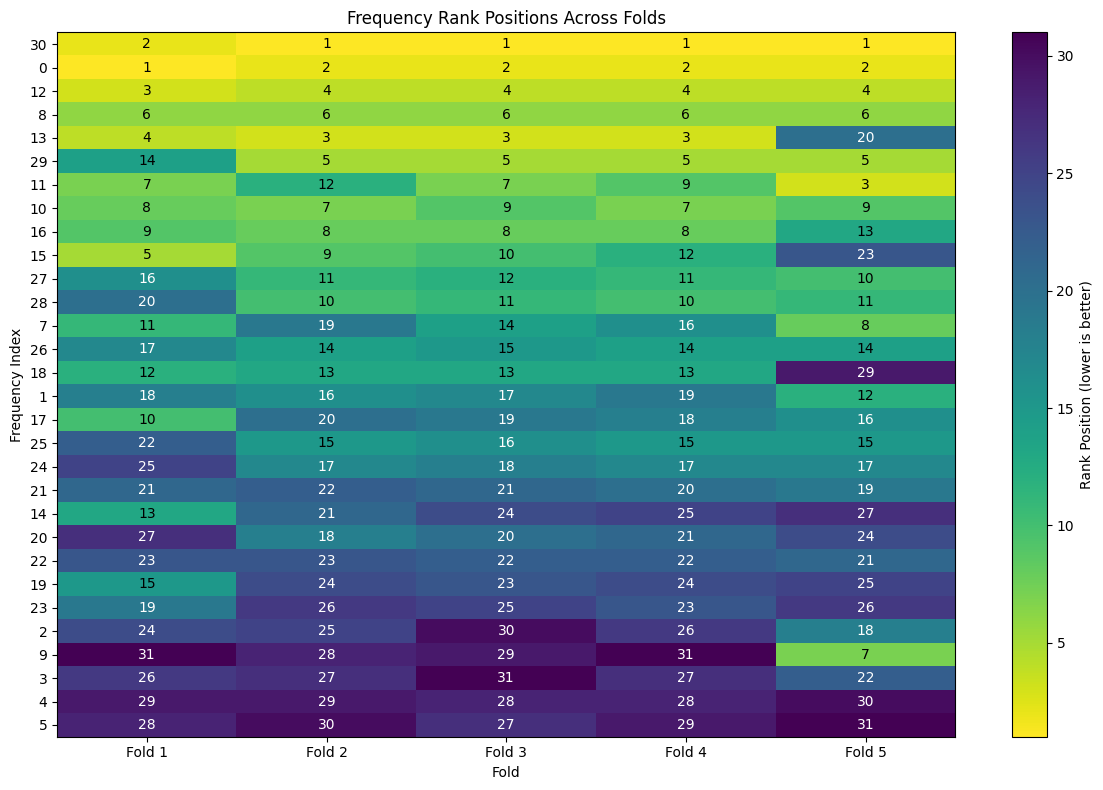

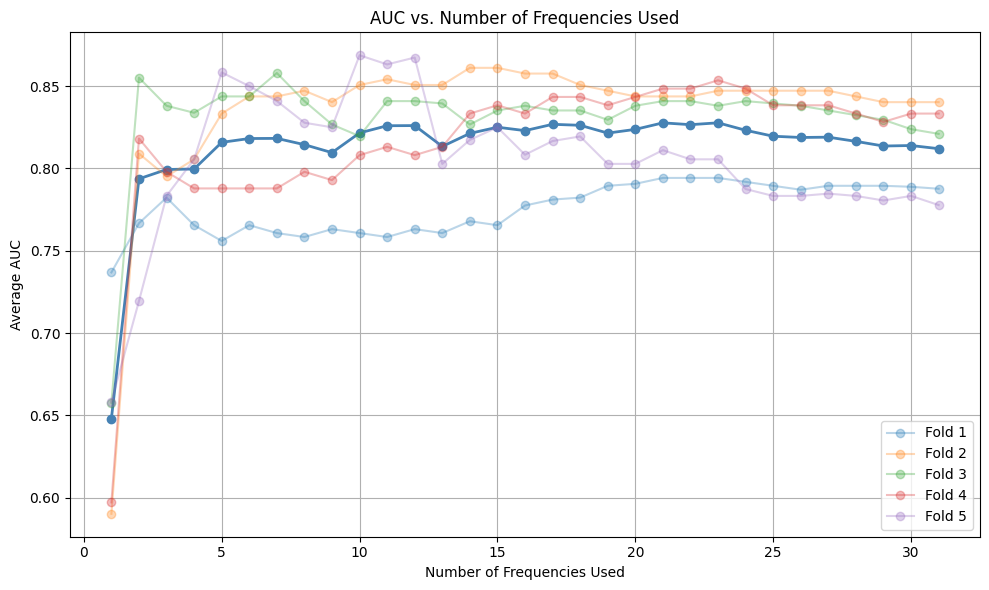

In [11]:
mask.IIVV_mask("vv_long_across_extended")
X_tmp = X[:, :, mask.mask]

aucs_lae, top_freqs_lae, fold_rankings_lae, fold_aucs_lae = (
    combined_frequency_roc_analysis(
        X_tmp, Y, Case, max_freqs=31, n_folds=5, random_state=random_state
    )
)

**4. Medium across extended `vv_medium_across_extended`**

config: vv_medium_across_extended={'26_31': [6, 7, 8, 16, 17, 18], '27_30': [8, 9, 10, 18, 19, 20], '28_33': [2, 4, 7, 9, 12, 14], '29_32': [12, 14, 17, 19, 22, 24], '30_26': [6, 7, 8, 18, 19, 20], '31_27': [8, 9, 10, 16, 17, 18], '32_28': [12, 14, 17, 19, 22, 24], '33_29': [2, 7, 12, 14, 19, 24]}


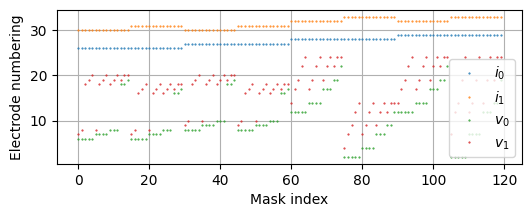

Mask set by IIVV pattern rule.
True: 120 (1.55%)	False: 7608(98.45%)
Performing 5-fold cross-validation with PCA-based frequency ranking and ROC analysis...
Train patients: [ 1  2  3  6  7  8  9 10 12 14 15 16 18 19 21 22 23 25 27 28 30 32 33 34
 35 36 37 39 40 41 44 45 46 48 49 50 51 52 53 54 55 56 57 59 60 61 62 63
 64 66 67 68 69 72 73 74 75 77 78 79 80 81 82 83 84 85 86 88 89 90 91 92
 94 96 97 99]
Test patients: [43 24 58 76  0 29 42 70 11 47 87 38 95 65 13  4 20 31]
Fold 1: 79.4% train / 20.6% test
Fold 1: 79.4% train / 20.6% test
  Training: 143 samples from 76 patients
  Testing:  37 samples from 18 patients
Fold 1 frequency ranking (top 10): [30 27  0 29 12 13 28 16 11 26]
Train patients: [ 0  1  2  3  4  7  8  9 11 13 14 15 19 20 21 22 23 24 25 27 28 29 30 31
 32 35 37 38 39 40 41 42 43 44 46 47 48 49 51 53 54 55 56 57 58 59 60 61
 62 63 64 65 66 67 70 75 76 77 78 79 80 83 84 85 86 87 88 89 90 91 92 94
 95 96 97 99]
Test patients: [52 68 16 72 82 33 36 12 69 73 34 81 10 74  6

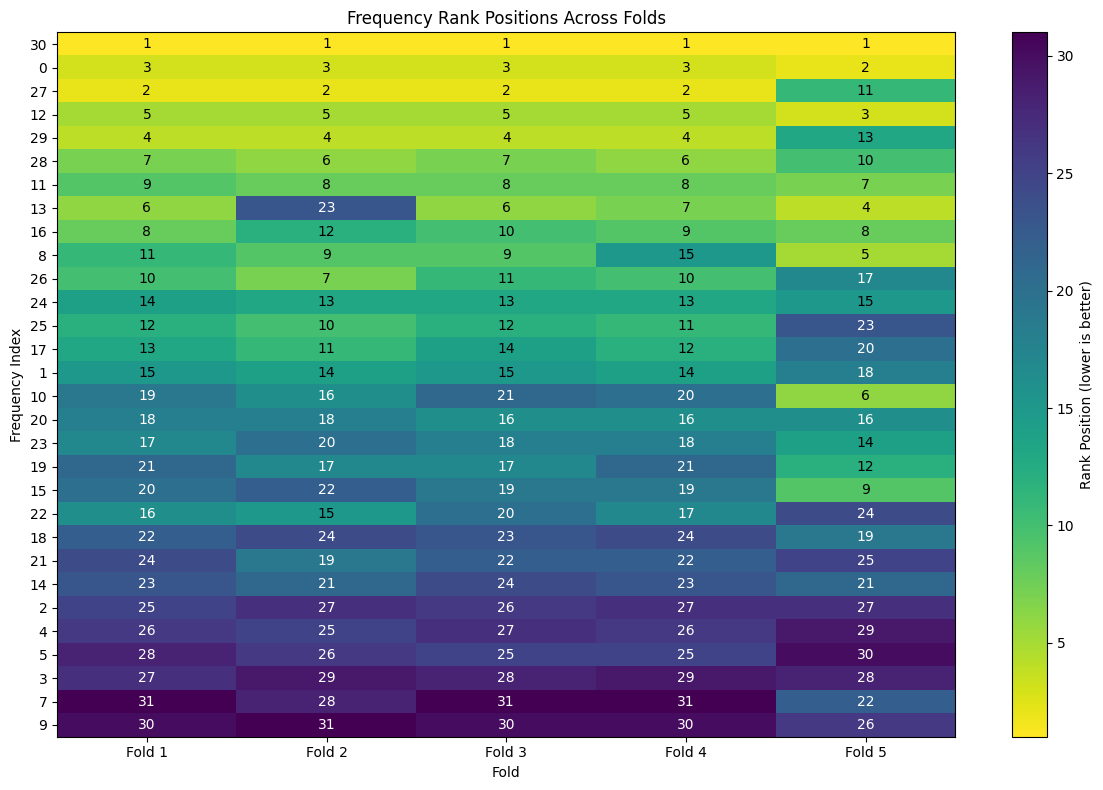

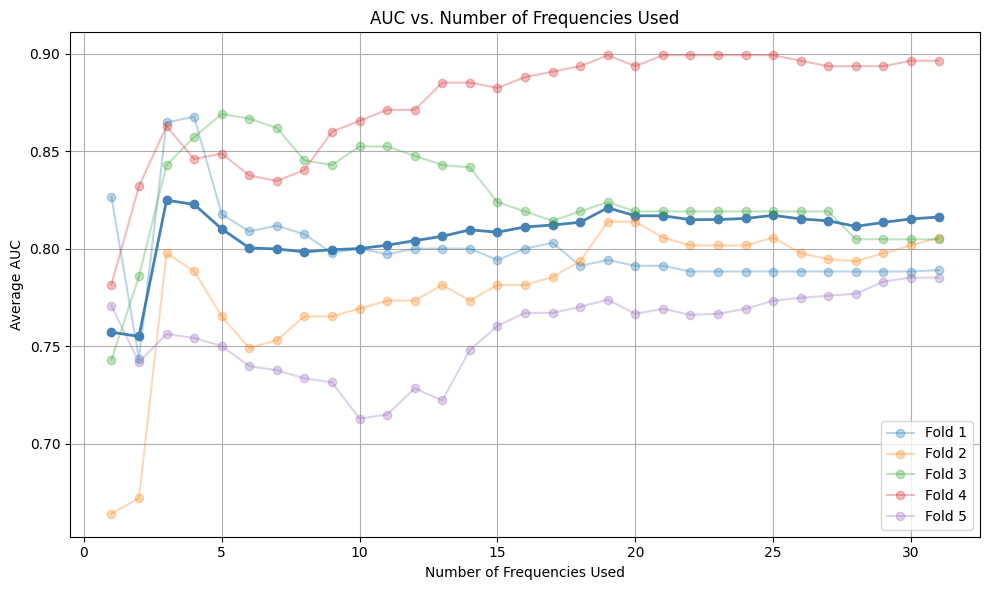

In [12]:
mask.IIVV_mask("vv_medium_across_extended")
X_tmp = X[:, :, mask.mask]

aucs_mae, top_freqs_mae, fold_rankings_mae, fold_aucs_mae = (
    combined_frequency_roc_analysis(
        X_tmp, Y, Case, max_freqs=31, n_folds=5, random_state=42
    )
)

**5. Distance close skip 1 `vv_distance_close_skip_1`**

config: vv_distance_close_skip_1={'26_28': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10], '27_29': [4, 5, 9, 10, 14, 15, 19, 20, 24, 25], '28_30': [4, 5, 9, 10, 14, 15, 19, 20, 24, 25], '29_31': [16, 17, 18, 19, 20, 21, 22, 23, 24, 25], '30_32': [16, 17, 18, 19, 20, 21, 22, 23, 24, 25], '31_33': [1, 2, 6, 7, 11, 12, 16, 17, 21, 22], '32_26': [1, 2, 6, 7, 11, 12, 16, 17, 21, 22], '33_27': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]}


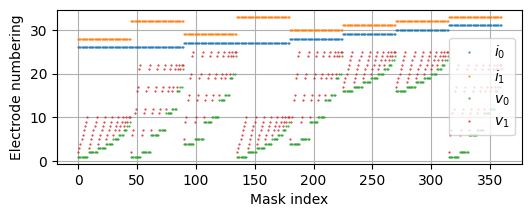

Mask set by IIVV pattern rule.
True: 360 (4.66%)	False: 7368(95.34%)
Performing 5-fold cross-validation with PCA-based frequency ranking and ROC analysis...
Train patients: [ 1  2  3  6  7  8  9 10 12 14 15 16 18 19 21 22 23 25 27 28 30 32 33 34
 35 36 37 39 40 41 44 45 46 48 49 50 51 52 53 54 55 56 57 59 60 61 62 63
 64 66 67 68 69 72 73 74 75 77 78 79 80 81 82 83 84 85 86 88 89 90 91 92
 94 96 97 99]
Test patients: [43 24 58 76  0 29 42 70 11 47 87 38 95 65 13  4 20 31]
Fold 1: 79.4% train / 20.6% test
Fold 1: 79.4% train / 20.6% test
  Training: 143 samples from 76 patients
  Testing:  37 samples from 18 patients
Fold 1 frequency ranking (top 10): [30  0 27 29 12 13 28 16 15 25]
Train patients: [ 0  1  2  3  4  7  8  9 11 13 14 15 19 20 21 22 23 24 25 27 28 29 30 31
 32 35 37 38 39 40 41 42 43 44 46 47 48 49 51 53 54 55 56 57 58 59 60 61
 62 63 64 65 66 67 70 75 76 77 78 79 80 83 84 85 86 87 88 89 90 91 92 94
 95 96 97 99]
Test patients: [52 68 16 72 82 33 36 12 69 73 34 81 10 74  6

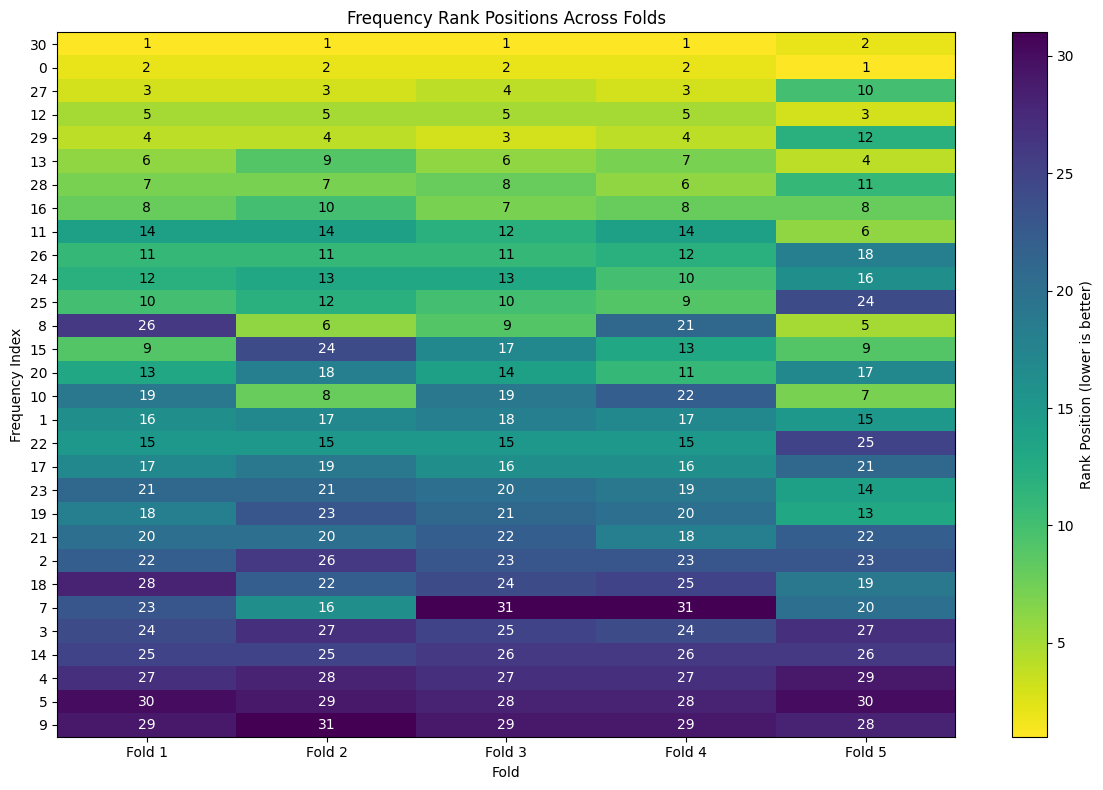

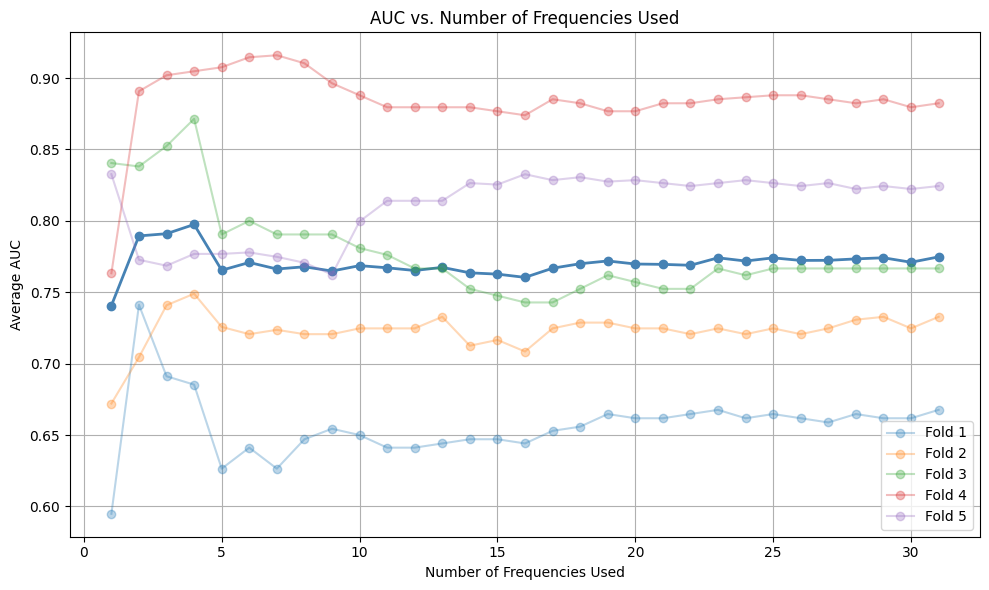

In [13]:
mask.IIVV_mask("vv_distance_close_skip_1")
X_tmp = X[:, :, mask.mask]

aucs_s1, top_freqs_s1, fold_rankings_s1, fold_aucs_s1 = combined_frequency_roc_analysis(
    X_tmp, Y, Case, max_freqs=31, n_folds=5, random_state=42
)

## Save/overview of results

In [14]:
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

color_palette_full = {
    "Healthy": "#003F5C",
    "Benign": "#58508D",
    "Dysplasia": "#7A5195",
    "Mild dysplasia": "#BC5090",
    "Non-cancer": "#DD5182",
    "Severe dysplasia": "#FF6361",
    "Cancer": "#FFA600",
}

custom_colors = list(color_palette_full.values())

custom_cmap = mcolors.ListedColormap(custom_colors, name="custom_disease_cmap")

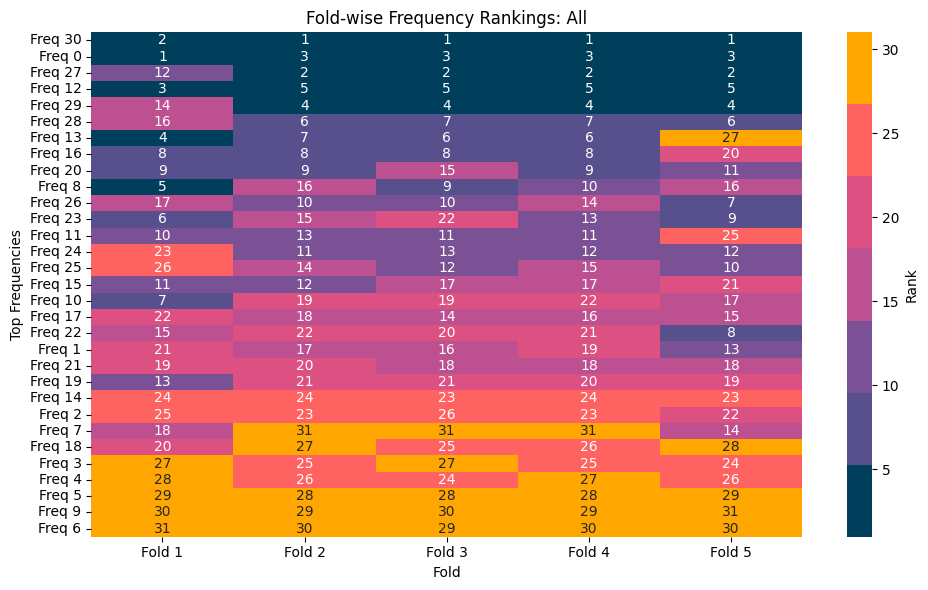

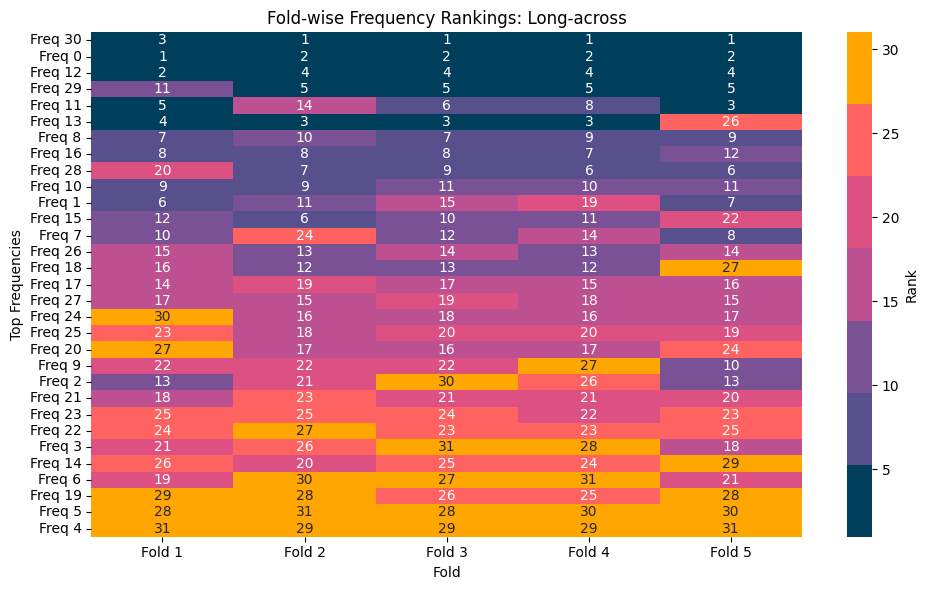

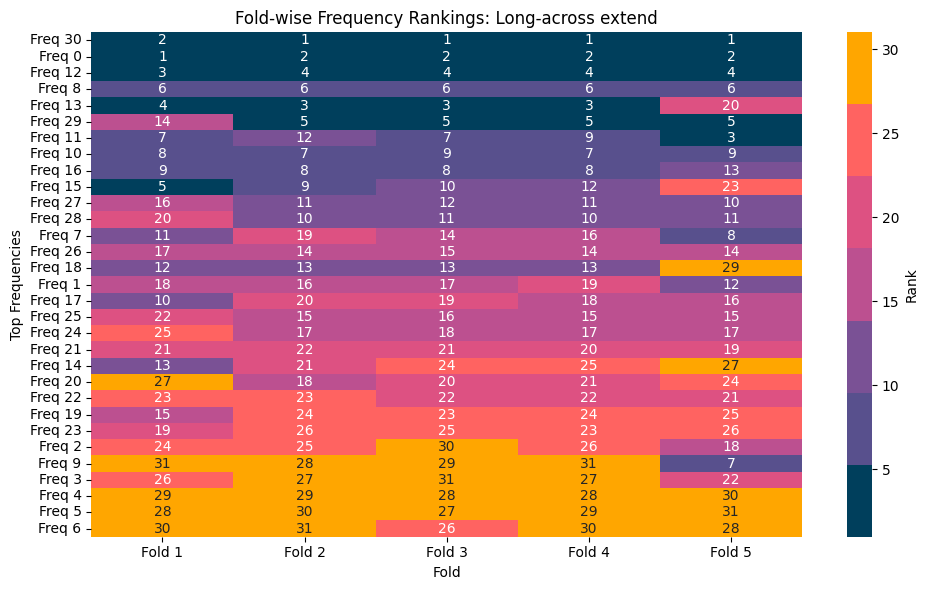

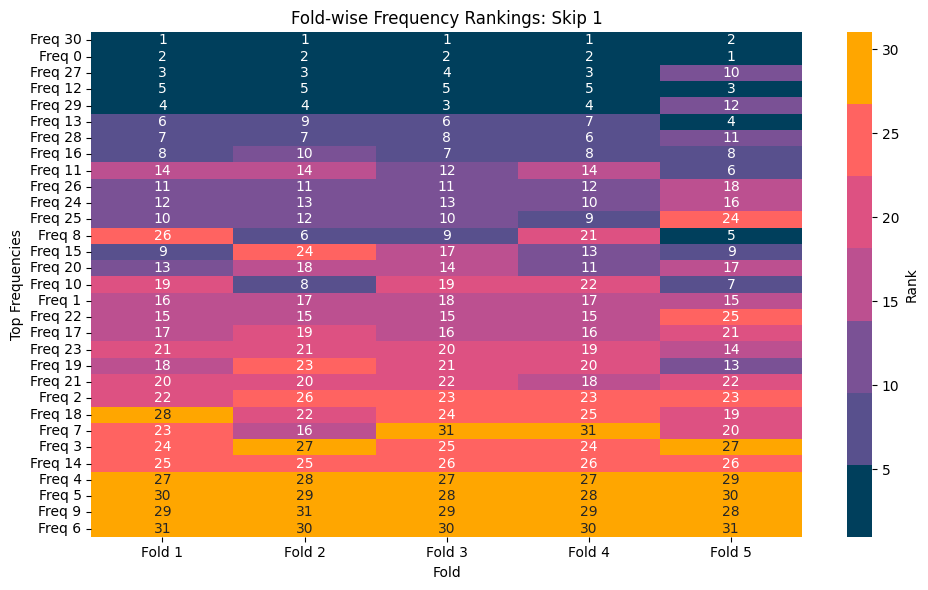

In [15]:
def plot_fold_rankings(fold_rankings_dict, top_n_freqs=20):
    """
    Visualizes fold frequency rankings as heatmaps for multiple ranking sets.

    Parameters:
        fold_rankings_dict : dict
            Dictionary where keys are method names and values are lists of np.arrays (fold rankings).
        top_n_freqs : int
            Number of top composite frequencies to display in the heatmap.
    """
    for name, rankings in fold_rankings_dict.items():
        n_folds = len(rankings)
        n_freqs = len(rankings[0])

        # Composite ranking across folds for sorting
        score_accumulator = np.zeros(n_freqs)
        for fold in rankings:
            for rank, freq_idx in enumerate(fold):
                score_accumulator[freq_idx] += n_freqs - rank

        composite_ranking = np.argsort(score_accumulator)[::-1][:top_n_freqs]

        # Create rank matrix: rows = top freqs, cols = folds
        rank_matrix = np.full((top_n_freqs, n_folds), np.nan)
        for f_idx, fold in enumerate(rankings):
            for i, freq in enumerate(composite_ranking):
                pos = np.where(fold == freq)[0]
                if pos.size > 0:
                    rank_matrix[i, f_idx] = pos[0] + 1  # +1 for 1-based rank

        # Plot heatmap
        plt.figure(figsize=(10, 6))
        sns.heatmap(
            rank_matrix,
            annot=True,
            fmt=".0f",
            cmap=custom_cmap,
            cbar_kws={"label": "Rank"},
            xticklabels=[f"Fold {i+1}" for i in range(n_folds)],
            yticklabels=[f"Freq {f}" for f in composite_ranking],
        )
        plt.title(f"Fold-wise Frequency Rankings: {name}")
        plt.xlabel("Fold")
        plt.ylabel("Top Frequencies")
        plt.tight_layout()
        plt.show()


fold_rankings_dict = {
    "All": fold_rankings_all,
    "Long-across": fold_rankings_la,
    "Long-across extend": fold_rankings_lae,
    "Skip 1": fold_rankings_s1,
}

plot_fold_rankings(fold_rankings_dict, top_n_freqs=31)

## Frequency input experiment

Since frequency 0 and 30 are the most consistent ones, I'd be curious to see how classification does with just those two frequencies.
Could you take the average of the rankings for each frequency and do a classification run through with the top 5, and then top 12 frequencies?
So in total, 4 different frequency inputs: top 2, top 5, top 12 and all 31 for control (baseline)

In [16]:
import matplotlib.pyplot as plt
import numpy as np
from toolbox import get_freqs

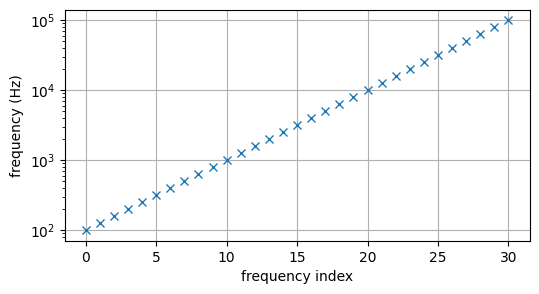

In [17]:
freq_idx, freq_list = get_freqs()

In [19]:
fold_rankings_dict["All"]

[array([ 0, 30, 12, 13,  8, 23, 10, 16, 20, 11, 15, 27, 19, 29, 22, 28, 26,
         7, 21, 18,  1, 17, 24, 14,  2, 25,  3,  4,  5,  9,  6]),
 array([30, 27,  0, 29, 12, 28, 13, 16, 20, 26, 24, 15, 11, 25, 23,  8,  1,
        17, 10, 21, 19, 22,  2, 14,  3,  4, 18,  5,  9,  6,  7]),
 array([30, 27,  0, 29, 12, 13, 28, 16,  8, 26, 11, 25, 24, 17, 20,  1, 15,
        21, 10, 22, 19, 23, 14,  4, 18,  2,  3,  5,  6,  9,  7]),
 array([30, 27,  0, 29, 12, 13, 28, 16, 20,  8, 11, 24, 23, 26, 25, 17, 15,
        21,  1, 19, 22, 10,  2, 14,  3, 18,  4,  5,  9,  6,  7]),
 array([30, 27,  0, 29, 12, 28, 26, 22, 23, 25, 20, 24,  1,  7, 17,  8, 10,
        21, 19, 16, 15,  2, 14,  3, 11,  4, 13, 18,  5,  6,  9])]

In [20]:
top_2 = np.array([30, 0])
top_5 = np.array([30, 0, 27, 12, 29])
top_12 = np.array([30, 0, 27, 12, 29, 28, 13, 16, 20, 8, 26, 23])

Text(0.5, 0, 'frequency index')

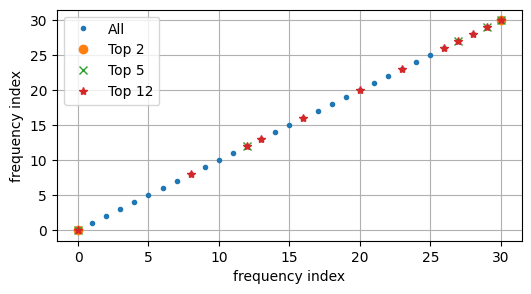

In [21]:
plt.figure(figsize=(6, 3))
plt.plot(freq_idx, ".", label="All")
plt.plot(top_2, top_2, "o", label="Top 2")
plt.plot(top_5, top_5, "x", label="Top 5")
plt.plot(top_12, top_12, "*", label="Top 12")
plt.legend()
plt.grid()
plt.ylabel("frequency index")
plt.xlabel("frequency index")

___